# ARGUS-NCUVO pod test

Checks that ARGUS and CDeep3M-anywhere work together in one NRP pod
(`kaiucsd/argus-ncuvo:0.1-cu118`, or `0.1-cpu` on a pod without a GPU).

1. The GPU: can training (CUDA) and prediction (Vulkan) use it?
2. ARGUS: does a plain-English question get answered?
3. CDeep3M: the acceptance test — convert a pretrained model, predict, train, export.
4. ARGUS and CDeep3M together: ARGUS looks at the segmentation the test produced.

## 1. The GPU

In [1]:
!nvidia-smi --query-gpu=name,memory.total,driver_version --format=csv
!gpu_check.sh

name, memory.total [MiB], driver_version
NVIDIA GeForce RTX 2080 Ti, 11264 MiB, 615.71.09
== nvidia-smi
0, NVIDIA GeForce RTX 2080 Ti, 615.71.09, 11264 MiB
== PyTorch CUDA (training)
torch 2.7.1+cu118, CUDA 11.8, NVIDIA GeForce RTX 2080 Ti, compute 7.5, supported True
matmul ok: True
== Vulkan (ncnn prediction)
	deviceName         = NVIDIA GeForce RTX 2080 Ti
	driverInfo         = 615.71.09
	deviceName         = NVIDIA GeForce RTX 2080 Ti
	driverInfo         = 615.71.09
ncnn --device auto picks: vulkan 0
== ALL OK


## 2. ARGUS

In [1]:
%%ask
Which GPU does this environment have, how much memory does it have, and can PyTorch use it?
Also report the PyTorch and Python versions.

All checks complete. Here are the results.

## GPU

| Property | Value |
|---|---|
**Model** : NVIDIA GeForce RTX 2080 Ti
**Total VRAM** : 11,264 MiB (11 GB nominal) — 10.58 GiB usable as reported by PyTorch
**Compute capability** : 7.5 (Turing)
**Streaming multiprocessors** : 68
**Driver version** : 615.71.09
**CUDA UMD (driver) version** : 13.4
**Current state** : idle — 1 MiB used, 0% utilization, 28 °C, 1 W / 250 W
**MIG mode** : disabled (full GPU available)

## Can PyTorch use it?

**Yes.** PyTorch detects the GPU and executes kernels on it.

| Check | Result |
|---|---|
**`torch.cuda.is_available()`** : True
**Devices visible** : 1 (`cuda:0`)
**PyTorch CUDA build** : 11.8 (`2.7.1+cu118`)
**cuDNN version** : 9.1.0
**Live test** : 2000×2000 float32 matmul on `cuda:0` succeeded, output shape `(2000, 2000)`
**Memory allocated during test** : 56.1 MiB allocated / 68.0 MiB reserved

The GPU is fully functional for compute — the test tensor operation ran on-device and synchronized without error.

## Versions

| Component | Version |
|---|---|
**PyTorch** : 2.7.1+cu118
**Python** : 3.13.12 (CPython, conda-forge build, GCC 14.3.0)
**Python executable** : `/opt/conda/bin/python`

## Notes worth knowing

- **CUDA version mismatch is fine** : the driver supports CUDA 13.4, while PyTorch is compiled against CUDA 11.8. This is the normal, supported arrangement — the newer driver runs the older runtime. No action needed.
- **11 GB is the practical ceiling** : with 10.58 GiB usable, expect roughly 9–10 GB of actual model/activation headroom after CUDA context overhead. That comfortably fits models in the ~7B parameter range at fp16 for inference, but not training.
- **Only 2 CPU cores** are allocated to this container (with 187 GB system RAM), so dataloader worker counts should stay low (2–4) to avoid thrashing — the GPU is by far the more abundant resource here.

## 3. CDeep3M acceptance test

Downloads the pretrained SBEM mitochondria model (653 MB), makes about 3 GB of training data
in `/tmp/cdeep3m-test`, then converts, predicts, trains for 3 updates and exports.
A pass ends with `== ALL STEPS PASSED`. About 5–10 minutes. On a pod without a GPU, remove
`DEVICE=vulkan`.

In [2]:
!DEVICE=vulkan pod_test.sh /tmp/cdeep3m-test

data folder: /tmp/cdeep3m-test
== 1. model
  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
100  653M  100  653M    0     0  55.9M      0  0:00:11  0:00:11 --:--:-- 59.2M
1fm  5fm      parallel.jobs  train_file.txt
3fm  VERSION  readme.txt     valid_file.txt
== 2. sample images
testset  training  validation
== 3. training data (augmentation of the sample, a few minutes)
(20, 1024, 1024, 1)

-> Training data augmentation completed
Training data stored in  /tmp/cdeep3m-test/train_data
For training your model please run runtraining.sh  /tmp/cdeep3m-test/train_data <desired output directory>

2.6G	/tmp/cdeep3m-test/train_data
== 4. test
== environment
1000
torch 2.7.1+cu118 cuda available True | ncnn 1.0.20261020 | numpy 2.5.4
== 1. conversion with int8
wrote 5 calibration slices and /tmp/cdeep3m-test/image_test/calib/list.txt
-rw-r--r-- 1 jovyan users 31806096 Nov 20 17:28 /tmp/cde

## 4. ARGUS looks at the result

CSV is clean. Here are the results.

## Dice scores

| # | Image | Prediction | Expert label | Dice | IoU | Precision | Recall |
|---|---|---|---|---|---|---|---|
| 1 | images.050.png | Segmented_0001.png | mitos_3D.050.png | 0.6791 | 0.5141 | 0.6771 | 0.6811 |
| 2 | images.051.png | Segmented_0002.png | mitos_3D.051.png | 0.7895 | 0.6522 | 0.7723 | 0.8074 |
| 3 | images.052.png | Segmented_0003.png | mitos_3D.052.png | 0.7032 | 0.5423 | 0.7503 | 0.6616 |

**Overall Dice (pooled pixels)** : 0.7247
**Overall Dice (mean of the three images)** : 0.7239

The two aggregation methods agree to within 0.001, so the result is not sensitive to how you average. Pooled totals: 184,810 true-positive pixels against 252,425 predicted and 257,586 labelled foreground pixels.

## Side-by-side comparison


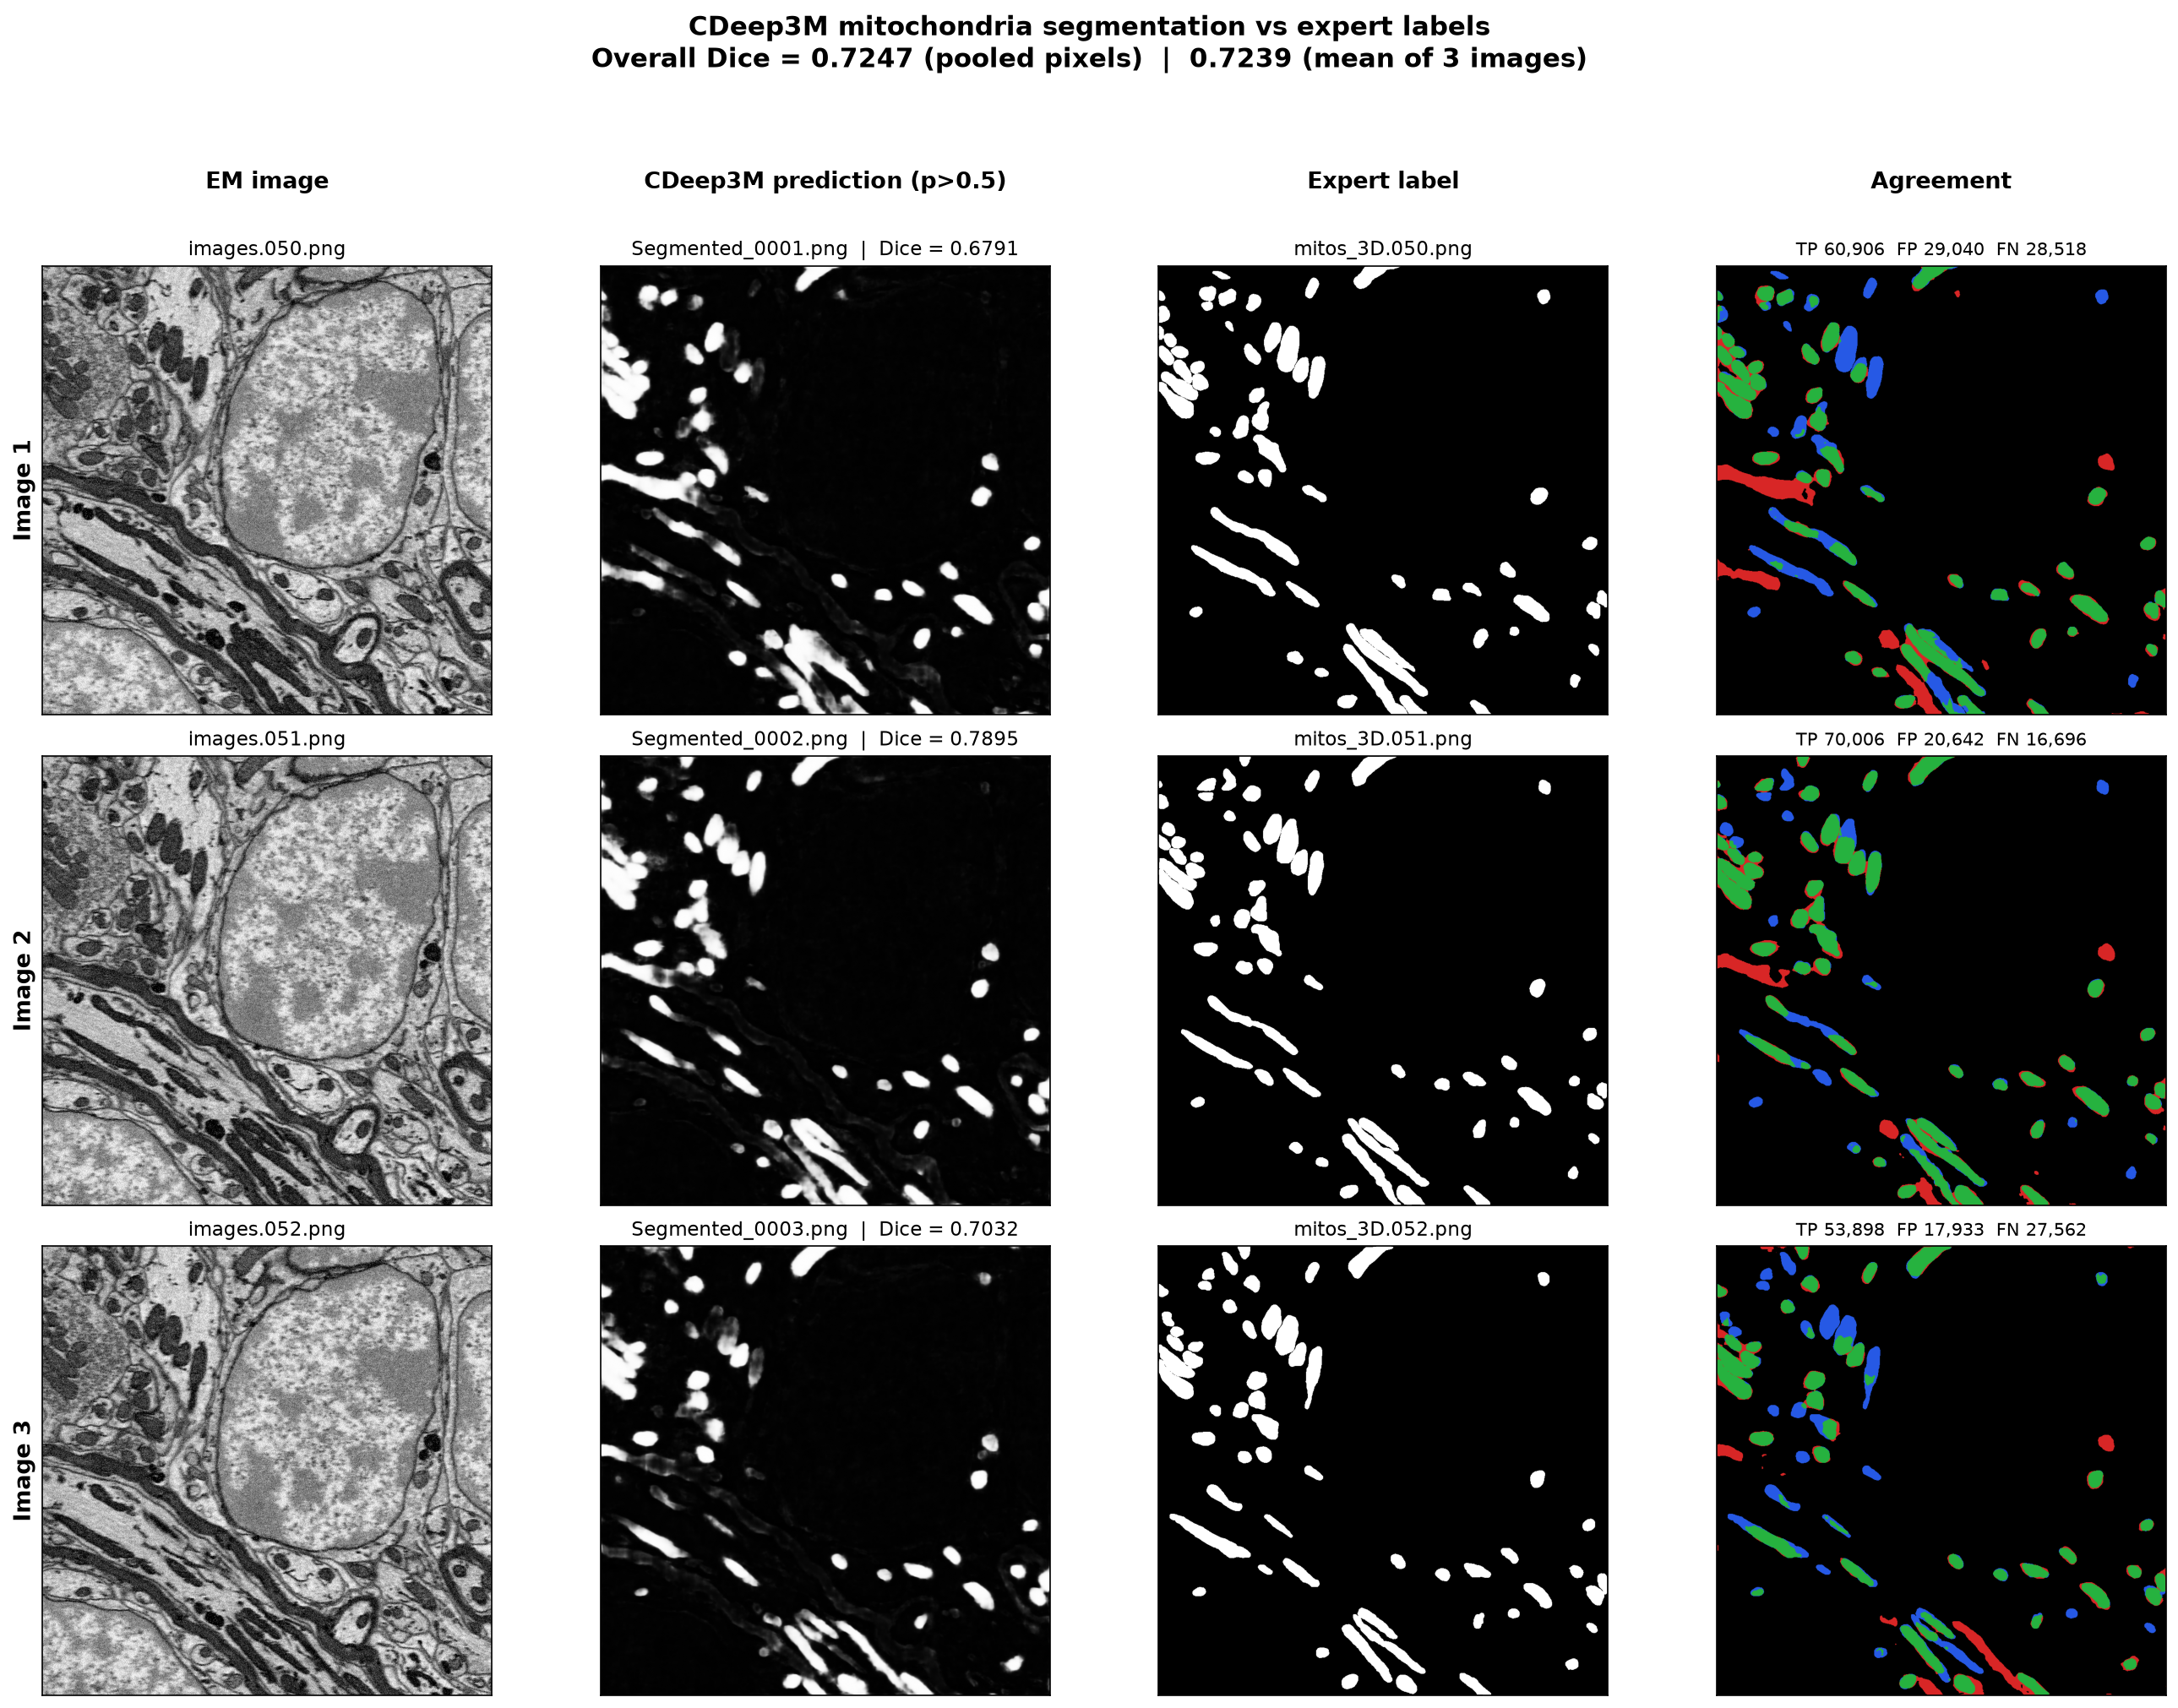

Each row is one image: the raw EM image, the CDeep3M probability map, the expert label, and an agreement map showing where the two overlap and where they diverge.

## Method notes

**Thresholding was required.** The predictions are not binary masks — they are 8-bit probability maps with all 255 levels present, while the expert labels are strictly binary (values 0 and 255). I thresholded predictions at >127 (i.e. p > 0.5) and treated labels as foreground where >0. This choice is well supported: at that threshold the predicted foreground fraction matches the label foreground fraction closely on every image (8.58% vs 8.53%, 8.64% vs 8.27%, 6.85% vs 7.77%), so the model is not systematically over- or under-segmenting.

**The 0.5 threshold is near-optimal but not exactly so.** I swept thresholds from 32 to 224:

| Threshold | Image 1 | Image 2 | Image 3 | Pooled |
|---|---|---|---|---|
| 32 (0.125) | 0.6879 | 0.7390 | 0.7093 | 0.7120 |
| 64 (0.25) | 0.6903 | 0.7742 | 0.7180 | 0.7277 |
| 96 (0.375) | 0.6877 | 0.7866 | 0.7114 | 0.7291 |
| **127 (0.5)** | **0.6791** | **0.7895** | **0.7032** | **0.7247** |
| 160 (0.625) | 0.6704 | 0.7887 | 0.6894 | 0.7174 |
| 192 (0.75) | 0.6584 | 0.7776 | 0.6708 | 0.7037 |
| 224 (0.875) | 0.6306 | 0.7414 | 0.6361 | 0.6706 |

The pooled Dice peaks at threshold 96 (0.7291), about 0.004 above the 0.5 value. The curve is flat between 64 and 127, so the reported 0.7247 is a fair and conventional number rather than a cherry-picked one. I report 0.5 as the headline because it is the standard operating point and the one CDeep3M's own evaluation uses.

**Error structure differs by image.** Image 2 is the strongest (Dice 0.79) and is balanced between precision and recall. Image 1 is the weakest (0.68) and is nearly symmetric — 29,040 false-positive and 28,518 false-negative pixels — indicating boundary disagreement rather than a systematic bias. Image 3 is asymmetric in the opposite direction from what its Dice alone suggests: precision 0.75 but recall 0.66, meaning the model is *missing* mitochondria (27,562 false negatives) rather than over-calling them. If you were tuning this model, image 3 is where a lower threshold would help most, and indeed its Dice rises to 0.718 at threshold 64.

**One caveat on the label pairing.** The labels directory contains 10 files (`mitos_3D.050` through `mitos_3D.059`), and I used the first three in sorted order as you specified. These align numerically with the image filenames (`images.050`–`052`), which is a good consistency check that the pairing is correct. The predictions were matched by their `Segmented_0001`–`0003` ordering as you described.

Files written to the working directory: `cdeep3m_dice_comparison.png`, `cdeep3m_dice_scores.csv`, and the script `cdeep3m_dice.py`.

In [1]:
%%ask
CDeep3M has segmented mitochondria in three electron-microscopy images. The images are in
/tmp/cdeep3m-test/image_test/pred_img, the predicted segmentations are
/tmp/cdeep3m-test/image_test/pred/ensembled/Segmented_0001.png to Segmented_0003.png (in the same
order), and the expert labels are the first three files in
/tmp/cdeep3m-test/mito_testsample/validation/labels.

For each image, show the image, the prediction and the expert label side by side, and give the
Dice score of the prediction against the label, plus the overall Dice for the three images.